# Predictive Forecasting of Care Load & Placement Demand

**Exploratory forecasting notebook** for HHS Unaccompanied Children Program daily records. It develops short-horizon forecasts for the active HHS care load and an indicative discharge-demand baseline, compares statistical and machine-learning approaches, and reports uncertainty and data limitations.

> **Decision-use note:** This notebook is a planning prototype, not an operational capacity system. The supplied extract has substantial gaps and ends on December 21, 2025. Forecasts need current data, program-owner review, and capacity thresholds before operational use.

## Executive summary and status

This notebook analyzes 720 dated records from **January 12, 2023 to December 21, 2025**. It compares persistence and moving-average baselines with exponential smoothing, SARIMA, random forest, and gradient boosting for HHS care load. The notebook includes the executed tables and charts from this run.

**Historical backtest:** SARIMA had the lowest MAE among the tested models in each lead band: 18.47 children at 1–7 days, 42.95 at 8–14 days, and 103.73 at 15–30 days. The persistence baseline MAE was 31.70, 62.59, and 119.85, respectively. Evaluation used seven rolling origins, so these are promising results that need more validation, not proof of operational accuracy. Prefer MAE/RMSE over the displayed “forecast accuracy” percentage.

**Forecast from this extract:** The selected SARIMA forecast starts on **December 22, 2025**, at 2,485 children and rises to about 2,557 by the end of the 30-day horizon. Those dates are now historical; this forecast must not be used as a current 2026 estimate. Refresh the source data and rerun the notebook for current planning.

**Important data limits:** 355 calendar dates are missing, and the weekday table has no Saturday records. Weekly patterns and forecasts over unobserved Saturdays are therefore uncertain. Flow measures are reported-day counts, not confirmed complete daily totals. The empirical error bands are not calibrated probability intervals, and capacity-breach probability cannot be estimated without an approved capacity threshold.

**Included files:** the companion CSV is in the same folder as this notebook. See `README.md` for how to open and rerun the analysis.


## 1. Questions and analysis plan

- How does the observed HHS care load evolve, and what weekly patterns are visible?
- How well do simple, statistical, and machine-learning forecasts perform at 1–7, 8–14, and 15–30 calendar-day lead times?
- What does a recent-discharge-rate baseline suggest, and how should it be interpreted when some reporting dates are absent?

The primary target is **Children in HHS Care**, a stock. The secondary target is **Children discharged from HHS Care**, a flow. Missing stock values are interpolated only to construct daily model inputs; all accuracy scores use actually observed HHS care-load dates. Missing flow values are never filled with zero. A 30-day rolling-origin evaluation is used to reduce dependence on a single split.

In [1]:
# Install dependencies in the active Jupyter environment if needed:
# %pip install pandas numpy matplotlib scikit-learn statsmodels

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.style.use("seaborn-v0_8-whitegrid")

## 2. Load and clean the source

The CSV is included beside this notebook for portability. The source file contains fully blank rows; these are dropped. We retain all dated rows, parse numbers with comma thousands separators, and fail loudly if duplicate dates or missing required fields remain.

In [2]:
DATA_PATH = Path("HHS_Unaccompanied_Alien_Children_Program.csv")
if not DATA_PATH.exists():
    # Optional fallback when running from the project root.
    DATA_PATH = Path("outputs") / DATA_PATH.name

raw = pd.read_csv(DATA_PATH, thousands=",")
blank_rows = int(raw.isna().all(axis=1).sum())
df = raw.dropna(how="all").copy()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

column_map = {
    "Children apprehended and placed in CBP custody*": "cbp_intake",
    "Children in CBP custody": "cbp_care",
    "Children transferred out of CBP custody": "transfers_to_hhs",
    "Children in HHS Care": "hhs_care",
    "Children discharged from HHS Care": "discharges",
}
df = df.rename(columns=column_map)
value_cols = list(column_map.values())
for col in value_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

assert df["Date"].notna().all(), "Some nonblank rows have invalid dates."
assert not df["Date"].duplicated().any(), "Duplicate dates require investigation before modeling."
assert df[value_cols].notna().all().all(), "Missing metric values remain after parsing."
df = df.sort_values("Date").set_index("Date")

summary = pd.Series({
    "Raw rows": len(raw),
    "Fully blank rows removed": blank_rows,
    "Dated observations": len(df),
    "First date": df.index.min().date(),
    "Last date": df.index.max().date(),
    "Calendar span (days)": (df.index.max() - df.index.min()).days + 1,
    "Missing calendar dates": len(pd.date_range(df.index.min(), df.index.max(), freq="D")) - len(df),
    "Repeated dates": int(df.index.duplicated().sum()),
})
summary.to_frame("Value")

,Value
Raw rows,1170
Fully blank rows removed,450
Dated observations,720
First date,2023-01-12
Last date,2025-12-21
Calendar span (days),1075
Missing calendar dates,355
Repeated dates,0


In [3]:
gap_days = df.index.to_series().diff().dt.days.dropna()
gap_summary = gap_days.describe(percentiles=[.5, .75, .9, .95, .99]).to_frame("Days between observations")
print(f"Consecutive calendar-day observations: {(gap_days == 1).sum():,} / {len(gap_days):,} ({(gap_days == 1).mean():.1%})")
print(f"Longest reporting gap: {gap_days.max():.0f} days")
print("Observations by year:")
display(df.groupby(df.index.year).size().rename("records").to_frame())
display(gap_summary)

Consecutive calendar-day observations: 558 / 719 (77.6%)
Longest reporting gap: 10 days
Observations by year:


,records
Date,
2023,230
2024,251
2025,239


,Days between observations
count,719.00
mean,1.49
std,1.00
min,1.00
50%,1.00
75%,1.00
90%,3.00
95%,3.00
99%,4.00
max,10.00


## 3. Explore observed series and missingness

A missing date is not evidence of zero intake, zero transfers, or zero discharges. For this reason, flow series below show only reported values. HHS care load is a stock and can be interpolated across short gaps as an explicit modeling assumption.

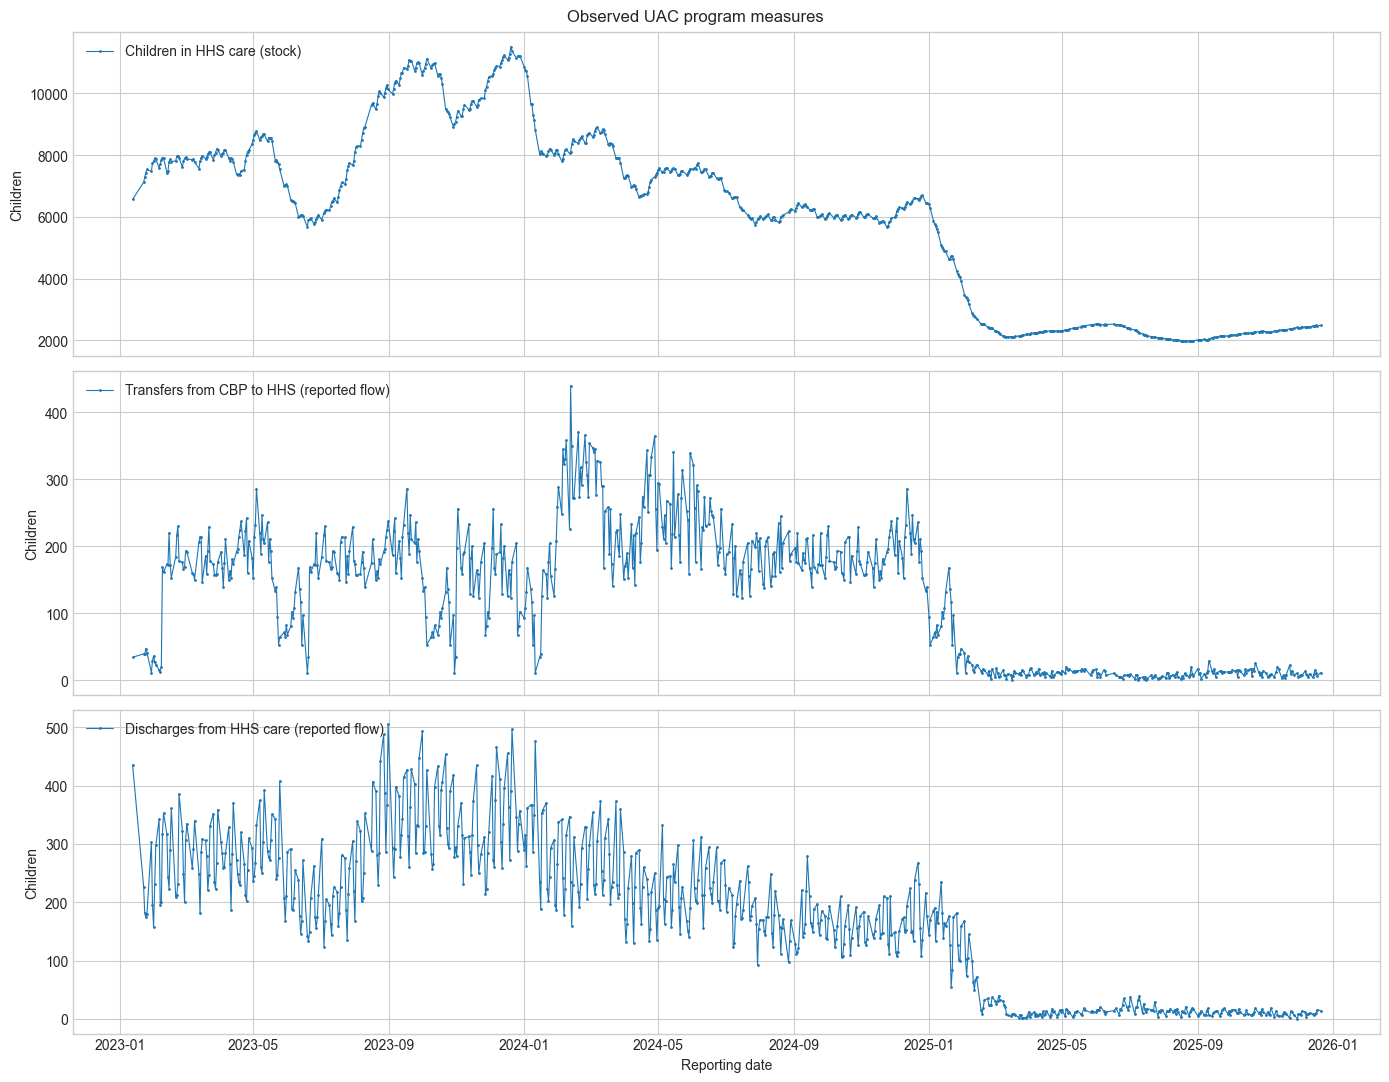

,observed fraction
cbp_intake,1.00
cbp_care,1.00
transfers_to_hhs,1.00
hhs_care,1.00
discharges,1.00


In [4]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
for col, label, ax in zip(
    ["hhs_care", "transfers_to_hhs", "discharges"],
    ["Children in HHS care (stock)", "Transfers from CBP to HHS (reported flow)", "Discharges from HHS care (reported flow)"],
    axes,
):
    ax.plot(df.index, df[col], marker=".", markersize=2, linewidth=0.8, label=label)
    ax.set_ylabel("Children")
    ax.legend(loc="upper left")
axes[-1].set_xlabel("Reporting date")
fig.suptitle("Observed UAC program measures")
plt.tight_layout()
plt.show()

coverage = df.notna().mean().rename("observed fraction")
coverage.to_frame()

### Daily index and interpolation policy

We reindex to all calendar dates. Only `hhs_care` is time-interpolated for model inputs. Flows remain missing on unreported dates and are excluded from any daily-total interpretation.

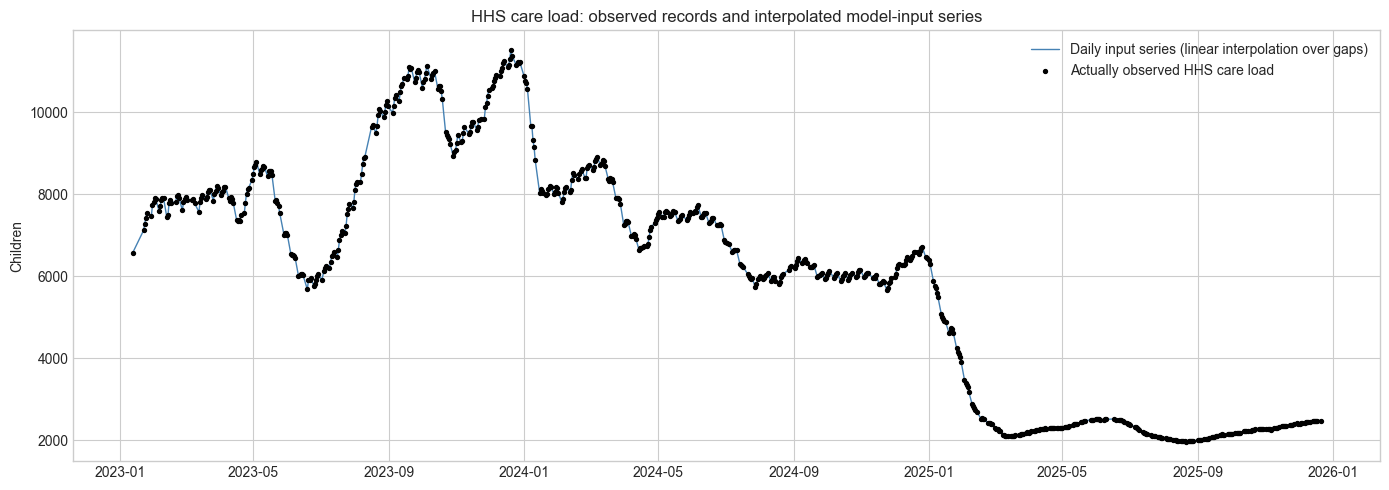

In [5]:
daily_index = pd.date_range(df.index.min(), df.index.max(), freq="D")
daily = df.reindex(daily_index)
daily.index.name = "Date"
observed_hhs = df["hhs_care"].copy()
hhs_daily = daily["hhs_care"].interpolate(method="time")
observed_mask = daily["hhs_care"].notna()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(hhs_daily.index, hhs_daily, color="steelblue", linewidth=1, label="Daily input series (linear interpolation over gaps)")
ax.scatter(observed_hhs.index, observed_hhs, s=8, color="black", label="Actually observed HHS care load", zorder=3)
ax.set_title("HHS care load: observed records and interpolated model-input series")
ax.set_ylabel("Children")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Trend and weekly seasonality

The decomposition is descriptive, not proof of a stable weekly process. It uses the interpolated stock series and a 7-day period; interpret seasonal estimates cautiously because the data contain reporting gaps and likely operational changes.

**Coverage warning:** the source has no Saturday observations. The decomposition necessarily uses interpolated values for those dates, so the weekly component may reflect reporting coverage as well as real program behavior. Do not treat it as evidence of a Saturday pattern.


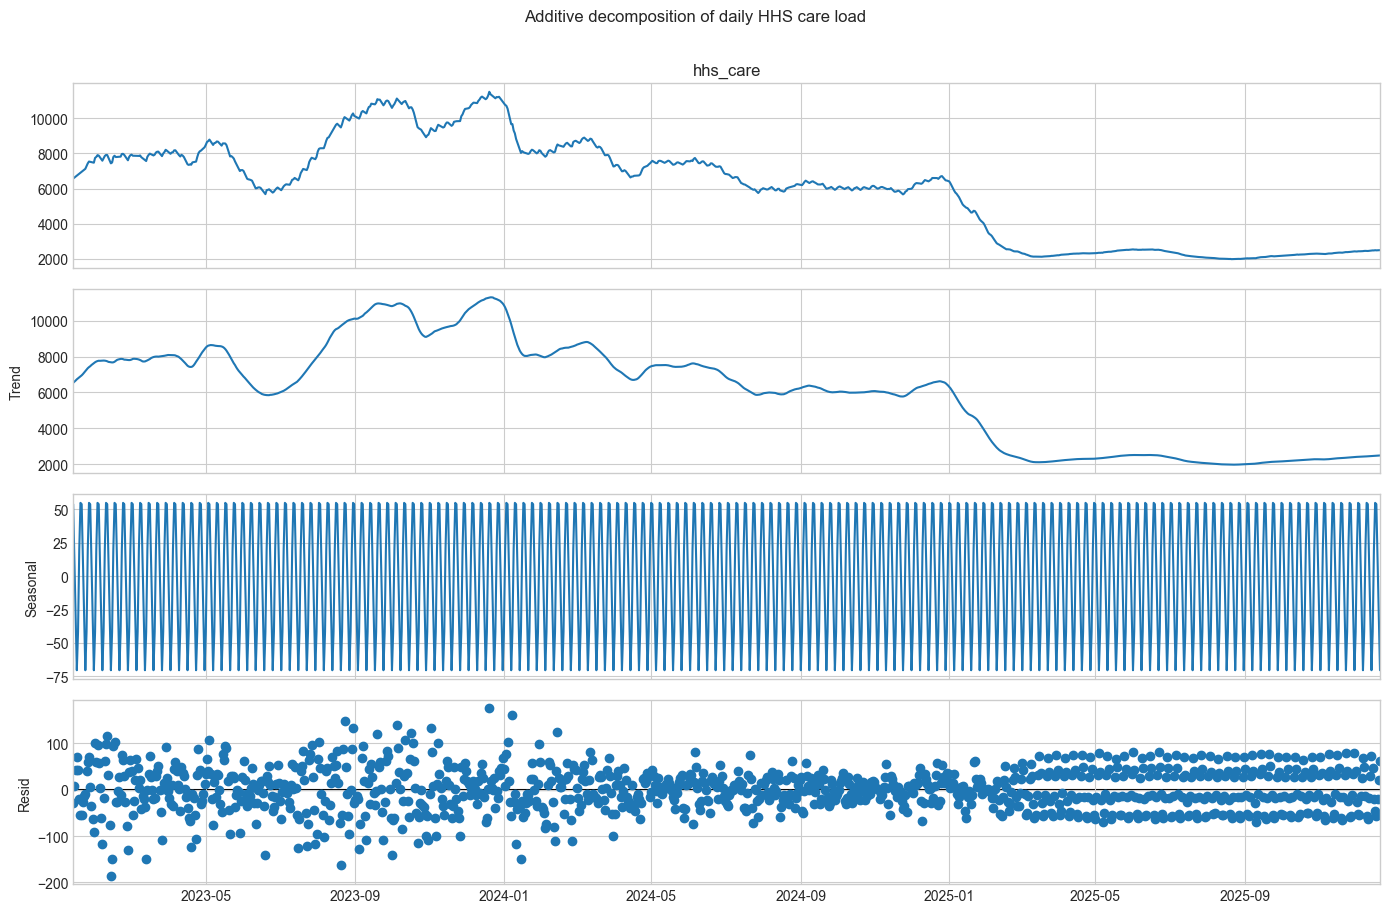

,transfers_to_hhs,discharges
Reporting weekday,,
Monday,123.70,157.60
Tuesday,124.90,136.10
Wednesday,131.70,166.00
Thursday,133.40,205.70
Friday,110.00,144.00
Saturday,NaN,NaN
Sunday,130.10,206.10


In [6]:
from statsmodels.tsa.seasonal import seasonal_decompose

components = seasonal_decompose(hhs_daily, model="additive", period=7, extrapolate_trend="freq")
fig = components.plot()
fig.set_size_inches(14, 9)
fig.suptitle("Additive decomposition of daily HHS care load", y=1.01)
plt.tight_layout()
plt.show()

weekly = df[["transfers_to_hhs", "discharges"]].copy()
weekly["day_of_week"] = weekly.index.day_name()
display(weekly.groupby("day_of_week")[["transfers_to_hhs", "discharges"]].mean().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
).rename_axis("Reporting weekday").round(1))

## 5. Forecast models and walk-forward evaluation

Models: naïve persistence, 7-day moving-average baseline, additive damped-trend/weekly exponential smoothing, SARIMA(1,1,1)×(1,1,1,7), random forest, and gradient boosting. ML models use lags, rolling summaries, and calendar features. Their training labels are restricted to actually observed HHS care-load dates; interpolated values are used only as lag inputs.

At each validation origin, models see data available up to that date and forecast the next 30 calendar days. Forecasts are scored only when the source has an observed HHS care value. The walk-forward origins are spaced 28 calendar days apart in the final 20% of observed records. Metrics by lead-time band summarize short, medium, and longer horizon performance.

In [7]:
def make_features(series):
    X = pd.DataFrame(index=series.index)
    for lag in (1, 7, 14):
        X[f"lag_{lag}"] = series.shift(lag)
    shifted = series.shift(1)
    for window in (7, 14):
        X[f"mean_{window}"] = shifted.rolling(window).mean()
        X[f"std_{window}"] = shifted.rolling(window).std()
    X["day_of_week"] = X.index.dayofweek
    X["month"] = X.index.month
    X["day_of_year"] = X.index.dayofyear
    return X

def recursive_ml_forecast(history, observed_history, horizon, model_kind):
    features = make_features(history)
    usable = observed_history.reindex(history.index).fillna(False) & features.notna().all(axis=1)
    X_train, y_train = features.loc[usable], history.loc[usable]
    if model_kind == "Random Forest":
        model = RandomForestRegressor(n_estimators=250, min_samples_leaf=3, max_features=0.9, random_state=42, n_jobs=-1)
    else:
        model = GradientBoostingRegressor(n_estimators=150, learning_rate=0.03, max_depth=2, loss="huber", random_state=42)
    model.fit(X_train, y_train)
    extended = history.copy()
    preds = []
    future_index = pd.date_range(history.index[-1] + pd.Timedelta(days=1), periods=horizon, freq="D")
    for date in future_index:
        row = make_features(extended).iloc[[-1]].copy()
        row.index = [date]
        pred = float(model.predict(row)[0])
        preds.append(pred)
        extended.loc[date] = pred
    return pd.Series(preds, index=future_index)

def forecast_all(history_observed, horizon=30):
    """Fit at one origin. history_observed is the actual, irregularly observed HHS stock."""
    last_date = history_observed.index.max()
    full_index = pd.date_range(history_observed.index.min(), last_date, freq="D")
    history = history_observed.reindex(full_index).interpolate(method="time")
    observed_flags = history_observed.reindex(full_index).notna()
    future_index = pd.date_range(last_date + pd.Timedelta(days=1), periods=horizon, freq="D")
    out = {}
    out["Naive persistence"] = pd.Series(float(history.iloc[-1]), index=future_index)
    out["7-day moving average"] = pd.Series(float(history.iloc[-7:].mean()), index=future_index)
    try:
        fit = ExponentialSmoothing(history, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7, initialization_method="estimated").fit(optimized=True)
        out["Exponential smoothing"] = pd.Series(np.asarray(fit.forecast(horizon)), index=future_index)
    except Exception as exc:
        print("Exponential smoothing skipped:", exc)
    try:
        fit = SARIMAX(history, order=(1, 1, 1), seasonal_order=(1, 1, 1, 7), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=150)
        out["SARIMA"] = pd.Series(np.asarray(fit.forecast(horizon)), index=future_index)
    except Exception as exc:
        print("SARIMA skipped:", exc)
    for kind in ("Random Forest", "Gradient Boosting"):
        try:
            out[kind] = recursive_ml_forecast(history, observed_flags, horizon, kind)
        except Exception as exc:
            print(f"{kind} skipped:", exc)
    return pd.DataFrame(out)

# Define final 20% of observed records as the rolling-origin evaluation window.
cut_position = int(np.floor(0.80 * len(observed_hhs)))
validation_start = observed_hhs.index[cut_position]
eval_dates = observed_hhs.index[observed_hhs.index >= validation_start]
origin_dates = list(pd.date_range(validation_start, observed_hhs.index.max() - pd.Timedelta(days=30), freq="28D"))
# Ensure at least one origin even for a shorter data extract.
if not origin_dates:
    origin_dates = [validation_start]

records = []
for origin in origin_dates:
    history = observed_hhs.loc[observed_hhs.index <= origin]
    preds = forecast_all(history, horizon=30)
    actual = observed_hhs.reindex(preds.index)

    for model_name in preds.columns:
        model_preds = preds[model_name]
        for lead, (lo, hi) in {"1-7 days": (1, 7), "8-14 days": (8, 14), "15-30 days": (15, 30)}.items():
            dates = model_preds.index[
                (np.arange(1, len(model_preds) + 1) >= lo) &
                (np.arange(1, len(model_preds) + 1) <= hi)
            ]
            mask = actual.reindex(dates).notna()
            for date in dates[mask]:
                y = float(actual.loc[date])
                yhat = float(model_preds.loc[date])
                records.append({
                    "origin": origin,
                    "date": date,
                    "lead_band": lead,
                    "model": model_name,
                    "actual": y,
                    "forecast": yhat,
                    "error": yhat - y,
                    "abs_error": abs(yhat - y),
                    "sq_error": (yhat - y) ** 2,
                    "ape": abs(yhat - y) / abs(y) if y != 0 else np.nan
                })
wf = pd.DataFrame(records)
if wf.empty:
    raise ValueError("No observed validation targets fell within forecast windows. Extend the horizon or check date coverage.")
metrics = (wf.groupby(["model", "lead_band"])
    .agg(n=("abs_error", "size"), MAE=("abs_error", "mean"), MSE=("sq_error", "mean"), MAPE=("ape", "mean"))
    .assign(RMSE=lambda x: np.sqrt(x.pop("MSE")), **{"Forecast accuracy (%)": lambda x: 100*(1-x["MAPE"])})
    .drop(columns="MAPE")
    .reset_index())
metrics["Forecast accuracy (%)"] = metrics["Forecast accuracy (%)"].clip(lower=0)
display(metrics.sort_values(["lead_band", "MAE"]).round(2))
print(f"Validation observations: {wf['date'].nunique():,}; rolling origins: {len(origin_dates)}; validation begins {validation_start.date()}.")

,model,lead_band,n,MAE,RMSE,Forecast accuracy (%)
15,SARIMA,1-7 days,30,18.47,36.78,99.22
9,Naive persistence,1-7 days,30,31.70,45.52,98.56
12,Random Forest,1-7 days,30,39.85,54.15,98.18
0,7-day moving average,1-7 days,30,47.82,65.61,97.82
3,Exponential smoothing,1-7 days,30,62.62,67.91,97.13
6,Gradient Boosting,1-7 days,30,143.81,175.21,93.17
16,SARIMA,15-30 days,73,103.73,132.82,95.43
4,Exponential smoothing,15-30 days,73,111.97,138.30,95.05
10,Naive persistence,15-30 days,73,119.85,134.97,94.59
13,Random Forest,15-30 days,73,131.57,148.66,94.03


Validation observations: 127; rolling origins: 7; validation begins 2025-05-14.


## 6. Select a model and produce a 30-day care-load forecast

The selection criterion below is lowest walk-forward MAE on 1–7-day lead forecasts, with a minimum sample count shown in the metrics. The selected method is then refit on all available observations. Prediction bands use the 90th percentile of absolute walk-forward errors from the matching lead-time band. These are empirical planning bands, not formal probabilistic guarantees.

Selected model by 1–7 day walk-forward MAE: SARIMA


,forecast,lower_90_empirical,upper_90_empirical
2025-12-22,"2,485.00","2,443.00","2,526.00"
2025-12-23,"2,487.00","2,445.00","2,528.00"
2025-12-24,"2,488.00","2,446.00","2,529.00"
2025-12-25,"2,487.00","2,446.00","2,529.00"
2025-12-26,"2,492.00","2,450.00","2,533.00"
2025-12-27,"2,496.00","2,455.00","2,537.00"
2025-12-28,"2,500.00","2,459.00","2,542.00"
2025-12-29,"2,501.00","2,414.00","2,589.00"
2025-12-30,"2,503.00","2,416.00","2,591.00"
2025-12-31,"2,505.00","2,418.00","2,592.00"


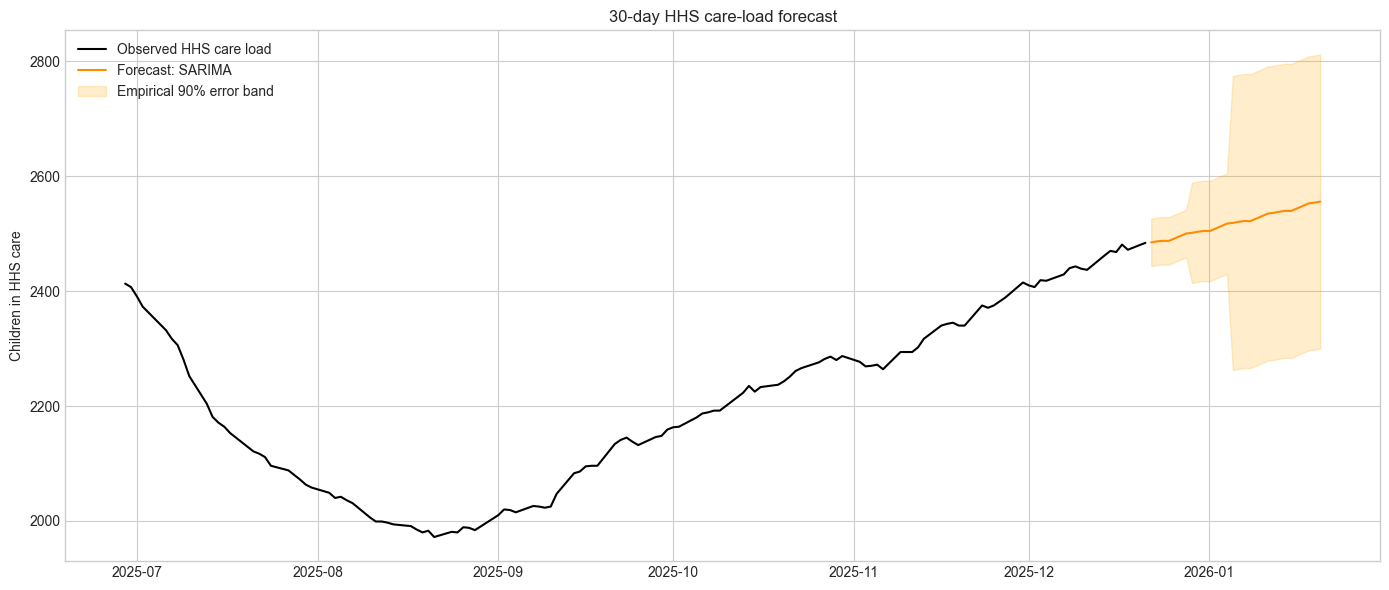

In [8]:
short_metrics = metrics[metrics["lead_band"] == "1-7 days"].sort_values("MAE")
selected_model = short_metrics.iloc[0]["model"]
final_forecasts = forecast_all(observed_hhs, horizon=30)
if selected_model not in final_forecasts:
    selected_model = final_forecasts.columns[0]

selected = final_forecasts[selected_model].rename("forecast")
lead = np.arange(1, len(selected) + 1)
q_by_band = {}
for band, lo, hi in [("1-7 days",1,7), ("8-14 days",8,14), ("15-30 days",15,30)]:
    errs = wf.loc[(wf.lead_band == band) & (wf.model == selected_model), "abs_error"]
    q_by_band[band] = float(errs.quantile(.90)) if len(errs) else float(wf.loc[wf.model == selected_model, "abs_error"].quantile(.90))
margin = np.array([q_by_band["1-7 days"] if h <= 7 else q_by_band["8-14 days"] if h <= 14 else q_by_band["15-30 days"] for h in lead])
forecast_table = pd.DataFrame({
    "forecast": selected,
    "lower_90_empirical": np.maximum(0, selected.values-margin),
    "upper_90_empirical": selected.values+margin,
})
print(f"Selected model by 1–7 day walk-forward MAE: {selected_model}")
display(forecast_table.head(14).round(0))

fig, ax = plt.subplots(figsize=(14, 6))
recent = observed_hhs.iloc[-120:]
ax.plot(recent.index, recent, color="black", label="Observed HHS care load")
ax.plot(forecast_table.index, forecast_table["forecast"], color="darkorange", label=f"Forecast: {selected_model}")
ax.fill_between(forecast_table.index, forecast_table["lower_90_empirical"], forecast_table["upper_90_empirical"], color="orange", alpha=.2, label="Empirical 90% error band")
ax.set_title("30-day HHS care-load forecast")
ax.set_ylabel("Children in HHS care")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Discharge-demand estimate

Because unreported discharge dates are unknown rather than zero, this section reports a **recent observed-day discharge baseline**: the mean over the last 14 recorded values. It is an expected count on a reported day under similar reporting conditions, not a reliable cumulative 7-day or 30-day total. The validation below compares a trailing-7-observation mean to observed discharges during the same rolling-origin windows; the observation count is shown so the metric cannot be mistaken for complete daily coverage.

Mean of last 14 reported discharge values: 9.6 children per reported day
Walk-forward trailing-7-observation baseline MAE: 5.3 children (132 observed targets across 7 origins)
Do not multiply this rate by calendar days to estimate total placements unless daily reporting completeness is confirmed.
Recent transfer rate baseline: 8.6; net-flow pressure baseline: -1.1 per reported day


,expected discharges per reported day,lower empirical band,upper empirical band
2025-12-22,9.60,0.20,19.10
2025-12-23,9.60,0.20,19.10
2025-12-24,9.60,0.20,19.10
2025-12-25,9.60,0.20,19.10
2025-12-26,9.60,0.20,19.10
2025-12-27,9.60,0.20,19.10
2025-12-28,9.60,0.20,19.10
2025-12-29,9.60,0.20,19.10
2025-12-30,9.60,0.20,19.10
2025-12-31,9.60,0.20,19.10


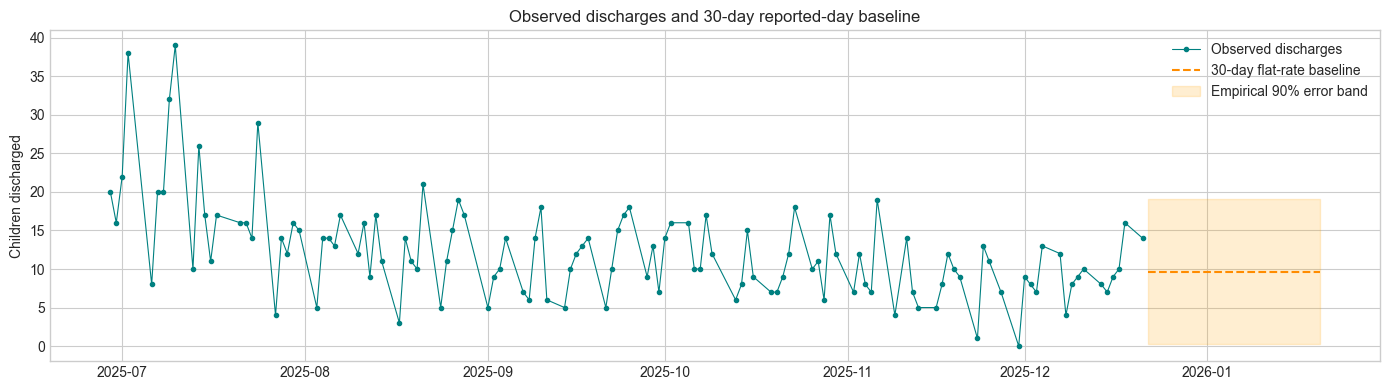

In [9]:
discharge = df["discharges"].dropna()
recent_discharge_rate = float(discharge.tail(14).mean())

# Evaluate a trailing-7-reported-observation forecast at the same origins.
discharge_rows = []
for origin in origin_dates:
    history = discharge.loc[discharge.index <= origin]
    if len(history) < 7:
        continue
    prediction = float(history.tail(7).mean())
    future = discharge.loc[(discharge.index > origin) & (discharge.index <= origin + pd.Timedelta(days=30))]
    for date, actual in future.items():
        discharge_rows.append({"origin": origin, "date": date, "actual": float(actual), "forecast": prediction, "abs_error": abs(float(actual)-prediction)})
discharge_wf = pd.DataFrame(discharge_rows)
discharge_mae = discharge_wf["abs_error"].mean() if len(discharge_wf) else np.nan
print(f"Mean of last 14 reported discharge values: {recent_discharge_rate:.1f} children per reported day")
print(f"Walk-forward trailing-7-observation baseline MAE: {discharge_mae:.1f} children ({len(discharge_wf):,} observed targets across {discharge_wf['origin'].nunique() if len(discharge_wf) else 0} origins)")
print("Do not multiply this rate by calendar days to estimate total placements unless daily reporting completeness is confirmed.")

# Flat-rate projection with an empirical error margin from the discharge walk-forward evaluation.
discharge_margin = float(discharge_wf["abs_error"].quantile(.90)) if len(discharge_wf) else np.nan
discharge_dates = pd.date_range(df.index.max() + pd.Timedelta(days=1), periods=30, freq="D")
discharge_forecast = pd.DataFrame({
    "expected discharges per reported day": recent_discharge_rate,
    "lower empirical band": max(0, recent_discharge_rate-discharge_margin),
    "upper empirical band": recent_discharge_rate+discharge_margin,
}, index=discharge_dates)
recent_transfer_rate = float(df["transfers_to_hhs"].tail(14).mean())
net_pressure_baseline = recent_transfer_rate - recent_discharge_rate
print(f"Recent transfer rate baseline: {recent_transfer_rate:.1f}; net-flow pressure baseline: {net_pressure_baseline:+.1f} per reported day")
display(discharge_forecast.head(14).round(1))

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(discharge.index[-120:], discharge.tail(120), marker=".", linewidth=.8, color="teal", label="Observed discharges")
ax.plot(discharge_forecast.index, discharge_forecast["expected discharges per reported day"], linestyle="--", color="darkorange", label="30-day flat-rate baseline")
ax.fill_between(discharge_forecast.index, discharge_forecast["lower empirical band"], discharge_forecast["upper empirical band"], color="orange", alpha=.18, label="Empirical 90% error band")
ax.set_title("Observed discharges and 30-day reported-day baseline")
ax.set_ylabel("Children discharged")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Net pressure, capacity stress, and early-warning design

A simple observed flow signal is **transfers to HHS minus discharges**. It is not an exact daily change in HHS care load because the two flows may have different timing, missingness, and definitions. The forecast data supplied here contain no shelter capacity, staffed beds, medical utilization, or caseworker workload thresholds. Therefore, a defensible capacity-breach probability or surge lead time cannot be computed from this CSV alone.

For a future operational version, connect verified capacity thresholds and complete daily flow reporting. Then flag an alert when the forecast upper band crosses capacity, and report the first crossing date and probability from calibrated forecast simulations.

In [10]:
flow = df[["transfers_to_hhs", "discharges"]].copy()
flow["net_flow_pressure"] = flow["transfers_to_hhs"] - flow["discharges"]
display(flow.tail(10).round(0))
print(f"Mean observed net flow pressure (reported dates only): {flow['net_flow_pressure'].mean():.1f} children")

# Optional capacity scenario: supply a verified program capacity number to calculate headroom.
# Example: CAPACITY = 5000  # replace with an approved, current operational threshold
CAPACITY = None
if CAPACITY is not None:
    first_crossing = forecast_table.index[forecast_table["upper_90_empirical"] >= CAPACITY]
    print("First upper-band crossing:", first_crossing[0].date() if len(first_crossing) else "none in 30-day horizon")
else:
    print("Capacity threshold not supplied; capacity-breach probability and surge lead time are not estimable.")

,transfers_to_hhs,discharges,net_flow_pressure
Date,,,
2025-12-08,9.00,4.00,5.00
2025-12-09,7.00,8.00,-1.00
2025-12-10,5.00,9.00,-4.00
2025-12-11,9.00,10.00,-1.00
2025-12-14,4.00,8.00,-4.00
2025-12-15,9.00,7.00,2.00
2025-12-16,15.00,9.00,6.00
2025-12-17,11.00,10.00,1.00
2025-12-18,6.00,16.00,-10.00


Mean observed net flow pressure (reported dates only): -44.7 children
Capacity threshold not supplied; capacity-breach probability and surge lead time are not estimable.


## 9. Findings, interpretation, and recommendations

### Findings from this run

- The file contained 1,170 raw rows; 450 fully blank rows were removed. The resulting 720 observations span 1,075 calendar days, leaving 355 dates without records. Dates are unique.
- Only 77.6% of adjacent observations are one calendar day apart; the longest reporting gap is 10 days. The weekday summary has no Saturday observations.
- SARIMA ranked first by MAE in all three displayed lead bands. Its MAE grows from 18.47 children at 1–7 days to 103.73 at 15–30 days. Gradient boosting performed substantially worse in this run.
- The selected model’s forecast is for December 22, 2025–January 20, 2026. Its first point estimate is 2,485 children; the final point is approximately 2,557. The error band widens with lead time.
- The last 14 reported discharge values average 9.6 children per reported day. The transfer baseline is 8.6, for a recent net-flow baseline of approximately −1.1 per reported day. This does not establish a complete calendar-day discharge total or an exact change in care load.

### How to use these results

Use the backtest as a model comparison for this historical data extract. The reported “Forecast accuracy (%)” is derived from MAPE and appears high partly because the HHS census is measured in thousands; it does not mean the forecast is correct 99% of the time. Report MAE and RMSE in children, alongside the forecast horizon and the number of validation observations.

The “empirical 90%” bands are based on historical absolute errors and are not guaranteed to contain 90% of future observations. Only seven rolling origins were used, and the validation dates overlap across forecast windows. Verify interval coverage on additional untouched periods before describing these as calibrated confidence intervals.

The weekly decomposition and SARIMA seasonal component require special caution: the source has no Saturday observations, so interpolated values supply part of the weekly series. The apparent weekly cycle may partly reflect the reporting schedule. Do not infer Saturday operations or capacity from it.

### Recommendations before operational use

1. Refresh the dataset through the latest reporting date, confirm whether missing dates mean non-reporting or zero activity, and investigate the absence of Saturdays.
2. Re-run evaluation with more rolling origins and a final untouched holdout; compare against the persistence and moving-average baselines. Check residuals and the actual coverage of forecast bands.
3. Confirm definitions and completeness for transfers and discharges before forecasting weekly placement totals or net flows.
4. Obtain approved facility capacity, staffing, and acuity measures before estimating capacity breaches, surge lead time, or staffing needs.
5. Treat this notebook as an analytical prototype until current data and program stakeholders validate it.


## 10. Reproducibility and extensions

The notebook is designed to run from its containing folder with the included CSV. Keep the data refresh date and source provenance with each run. Useful next steps are: more rolling origins; benchmark by operational season; tune SARIMA and ML hyperparameters only within time-ordered validation; predict daily transfer and discharge flows once reporting gaps are resolved; and add approved capacity limits for scenario analysis.